# Complexity analysis: preprocessing

In this notebook I analyze the algorithms of `src/preprocessing`: the cost of each line, the cost of the whole function, an optimized version and the comparison of the times.

Sizes used:

* R: rows of the raw file (136,989)
* c: columns of the raw file (54)
* R_t: rows of the tropical points
* R_s: rows of the selected curves (9,053)
* C: number of curves (940)
* m: points of one curve (about 10)

Rules of the S7 session: a line is O(1), a loop is the number of iterations times the cost of its body, the cost of a function is the sum of its lines, and only the biggest term is kept. The functions of pandas are not loops in Python, but they also have a cost.

In [1]:
import os
import sys
import timeit

sys.path.append(os.path.abspath(os.path.join("..", "..")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing.loading import load_raw
from src.preprocessing.cleaning import build_curve_data, clean_points, group_textures, build_curve_table, select_usable_curves, flag_upward_jumps
from src.preprocessing.optimized import build_curve_data_groupby


def measure(func, *args, repeats=3):
    return timeit.timeit(lambda: func(*args), number=repeats) / repeats

## 1. Analysis of the algorithms

### load_raw

```python
def load_raw():
    """Read the raw GSHP file. If it is not in data/raw, it is read from GitHub."""
    if os.path.exists(RAW_FILE):
        return pd.read_csv(RAW_FILE, encoding="latin-1", low_memory=False)
    return pd.read_csv(RAW_URL, encoding="latin-1", low_memory=False)
```

* `if os.path.exists(RAW_FILE)`: O(1)
* `return pd.read_csv(RAW_FILE, ...)`: O(R c), every cell of the file is read once
* the last line (reading from GitHub) is also O(R c)

**Total:** O(R c) in time and O(R c) in space, because the whole table is kept in memory.

### clean_points

```python
def clean_points(raw):
    """Remove bad rows and keep the tropical points. Returns the points and the rows left after each step."""
    steps = [["raw file", len(raw), raw["layer_id"].nunique()]]

    points = raw.drop_duplicates()
    steps.append(["without duplicates", len(points), points["layer_id"].nunique()])

    points = points[points["data_flag"] == "good quality estimate"]
    steps.append(["good quality fits", len(points), points["layer_id"].nunique()])

    points = points.dropna(subset=["lab_wrc", "lab_head_m"])
    steps.append(["without missing values", len(points), points["layer_id"].nunique()])

    points = points[points["lab_head_m"] <= 100000]
    steps.append(["psi <= 100000 m", len(points), points["layer_id"].nunique()])

    ok = (points["lab_wrc"] >= 0) & (points["lab_wrc"] <= 1) & (points["lab_head_m"] >= 0)
    points = points[ok]
    steps.append(["physical range", len(points), points["layer_id"].nunique()])

    points = points[points["climate_classes"] == "Tropical"]
    steps.append(["tropical climate", len(points), points["layer_id"].nunique()])

    steps = pd.DataFrame(steps, columns=["step", "rows", "curves"])
    return points, steps
```

* `steps = [[...]]` with `len(raw)` and `nunique()`: O(R)
* `raw.drop_duplicates()`: O(R c), each row has c values to compare
* `points[points["data_flag"] == ...]`: O(R) the comparison and O(R) the selection
* `points.dropna(subset=...)`: O(R)
* `points[points["lab_head_m"] <= 100000]`: O(R)
* `ok = (...) & (...) & (...)`: O(R)
* `points[ok]`: O(R)
* `points[points["climate_classes"] == "Tropical"]`: O(R)
* the 6 `steps.append(...)` with `nunique()`: O(R) each one
* `pd.DataFrame(steps, ...)`: O(1), the table has only 7 rows

**Total:** O(R c), because of `drop_duplicates`. The other lines are a fixed number of O(R) passes.

### group_textures

```python
def group_textures(points):
    """Add the texture group of each point and remove the points without a valid texture."""
    labelled = points.copy()
    labelled["texture_group"] = labelled["tex_psda"].map(TEXTURE_MAP)
    labelled = labelled.dropna(subset=["texture_group"])
    return labelled
```

* `points.copy()`: O(R_t c)
* `labelled["tex_psda"].map(TEXTURE_MAP)`: O(R_t), a dictionary lookup is O(1)
* `dropna(subset=...)`: O(R_t)

**Total:** O(R_t c), because of the copy.

### build_curve_table

```python
def build_curve_table(labelled):
    """Make a table with one row per curve."""
    table = labelled.groupby("layer_id").agg(
        n_points=("lab_head_m", "size"),
        psi_min=("lab_head_m", "min"),
        psi_max=("lab_head_m", "max"),
        texture_group=("texture_group", "first"),
        profile_id=("profile_id", "first"),
        reference=("reference", "first"),
        alpha_csv=("alpha", "first"),
        n_csv=("n", "first"),
    )
    return table
```

* `labelled.groupby("layer_id")`: O(R_t)
* `.agg(...)` with 8 aggregations: O(R_t) each one
* sorting of the C keys of the groups: O(C log C)

**Total:** O(R_t + C log C).

### select_usable_curves

```python
def select_usable_curves(curve_table, labelled):
    """Keep the curves with at least 6 points that cover psi <= 1 m and psi >= 100 m."""
    usable = curve_table[(curve_table["n_points"] >= 6) & (curve_table["psi_min"] <= 1) & (curve_table["psi_max"] >= 100)]
    selected_points = labelled[labelled["layer_id"].isin(usable.index)]
    return usable, selected_points
```

* the three comparisons and the `&` on the C rows of the table: O(C)
* `curve_table[...]`: O(C)
* `labelled["layer_id"].isin(usable.index)`: O(R_t + C), pandas uses a hash table
* `labelled[...]`: O(R_t)

**Total:** O(R_t + C).

### flag_upward_jumps

```python
def flag_upward_jumps(usable, selected_points):
    """Mark the curves where theta rises more than 0.05 when psi increases."""
    selected_points = selected_points.sort_values(["layer_id", "lab_head_m"])
    change = selected_points.groupby("layer_id")["lab_wrc"].diff()
    jump = (change > 0.05).groupby(selected_points["layer_id"]).any()
    usable = usable.copy()
    usable["has_upward_jump"] = jump
    return usable
```

* `sort_values([...])`: O(R_s log R_s)
* `groupby(...).diff()`: O(R_s)
* `(change > 0.05)` and `groupby(...).any()`: O(R_s)
* `usable.copy()` and the new column: O(C)

**Total:** O(R_s log R_s), because of the sort.

### build_curve_data (first version)

```python
def build_curve_data(selected_points, layer_ids):
    """Make a dictionary layer_id -> (psi, theta) filtering the table once for each curve."""
    curve_data = {}
    for layer_id in layer_ids:
        sub = selected_points[selected_points["layer_id"] == layer_id]
        curve_data[layer_id] = (sub["lab_head_m"].values, sub["lab_wrc"].values)
    return curve_data
```

* `curve_data = {}`: O(1)
* `for layer_id in layer_ids`: C iterations
* `selected_points["layer_id"] == layer_id`: O(R_s) in each iteration
* `selected_points[...]`: O(R_s) in each iteration
* `sub[...].values`: O(m)
* `curve_data[layer_id] = (...)`: O(1)

**Total:** C (R_s + m) = O(C R_s). Since R_s is about C m, it is O(C^2 m): the time grows with the square of the number of curves.

## 2. Optimization: build_curve_data with one groupby

The first version looks for every curve in the whole table. With `groupby` the table is read only once.

### build_curve_data_groupby (optimized)

```python
def build_curve_data_groupby(selected_points):
    """Make the dictionary layer_id -> (psi, theta) with one groupby."""
    curve_data = {}
    for layer_id, sub in selected_points.groupby("layer_id"):
        curve_data[layer_id] = (sub["lab_head_m"].values, sub["lab_wrc"].values)
    return curve_data
```

* `selected_points.groupby("layer_id")`: O(R_s), one pass over the table
* `for layer_id, sub in ...`: C iterations
* `sub[...].values`: O(m)
* `curve_data[layer_id] = (...)`: O(1)

**Total:** O(R_s) + C O(m) = O(R_s). The space is the same, O(R_s).

Comparison: the first version is O(C R_s) and the optimized one is O(R_s). The search of each curve in the whole table is not repeated.

### Same result and times

In [2]:
points_table = pd.read_csv(os.path.join("..", "..", "data", "processed", "selected_points.csv"))
ids = list(points_table["layer_id"].unique())

first = build_curve_data(points_table, ids)
fast = build_curve_data_groupby(points_table)
same = all(np.array_equal(first[k][0], fast[k][0]) and np.array_equal(first[k][1], fast[k][1]) for k in first)
print("same curves:", set(first.keys()) == set(fast.keys()), "| same arrays:", same)

same curves: True | same arrays: True


In [3]:
sizes = [100, 200, 400, 800, len(ids)]
t_first = []
t_fast = []
rows_s = []
for k in sizes:
    chosen = ids[:k]
    subset = points_table[points_table["layer_id"].isin(chosen)]
    rows_s.append(len(subset))
    t_first.append(measure(build_curve_data, subset, chosen))
    t_fast.append(measure(build_curve_data_groupby, subset))

timing = pd.DataFrame({"C (curves)": sizes, "R_s (rows)": rows_s, "first version (s)": t_first, "groupby (s)": t_fast})
timing["speed-up"] = timing["first version (s)"] / timing["groupby (s)"]
timing.round(4)

,C (curves),R_s (rows),first version (s),groupby (s),speed-up
0,100,976,0.0344,0.0046,7.4987
1,200,2076,0.0711,0.0071,9.9838
2,400,4276,0.1754,0.0204,8.6017
3,800,7982,0.4240,0.0220,19.2919
4,940,9053,0.4500,0.0269,16.7592


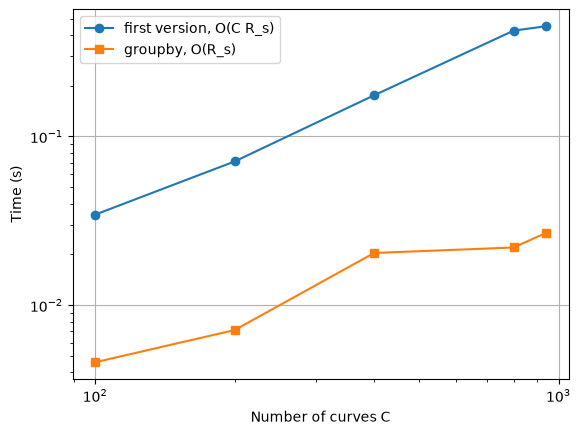

In [4]:
plt.loglog(sizes, t_first, "o-", label="first version, O(C R_s)")
plt.loglog(sizes, t_fast, "s-", label="groupby, O(R_s)")
plt.xlabel("Number of curves C")
plt.ylabel("Time (s)")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
print("with all the curves the speed-up is", round(timing["speed-up"].iloc[-1], 1), "times")
print("C grows", round(sizes[-1] / sizes[0], 1), "times, the first version grows",
      round(t_first[-1] / t_first[0], 1), "times and groupby grows", round(t_fast[-1] / t_fast[0], 1), "times")

with all the curves the speed-up is 16.8 times
C grows 9.4 times, the first version grows 13.1 times and groupby grows 5.8 times


The groupby version is faster for all the sizes. The time of the first version does not grow exactly with C^2 because, with this small table, each filter is fast and the fixed cost of every pandas call is a big part of the time. With a bigger table the difference would be larger.

## 3. Vectorized filter and loop

The filters of `clean_points` use vectorized pandas operations. As in the S2 session, I compare one of them (`psi <= 100000`) with a `for` loop. Both are O(R), but the constant is very different.

In [6]:
raw = load_raw()
psi = raw["lab_head_m"].dropna().values


def filter_loop(values):
    kept = []
    for v in values:
        if v <= 100000:
            kept.append(v)
    return np.array(kept)


def filter_vectorized(values):
    return values[values <= 100000]


sizes_f = [10000, 40000, 160000]
t_loop = []
t_vec = []
for size in sizes_f:
    part = np.resize(psi, size)
    t_loop.append(measure(filter_loop, part))
    t_vec.append(measure(filter_vectorized, part))
    print(size, "same result:", np.array_equal(filter_loop(part), filter_vectorized(part)))

pd.DataFrame({"rows": sizes_f, "loop (s)": t_loop, "vectorized (s)": t_vec, "speed-up": np.array(t_loop) / np.array(t_vec)}).round(5)

10000 same result: True
40000 same result: True
160000 same result: True


,rows,loop (s),vectorized (s),speed-up
0,10000,0.00103,0.00002,58.80306
1,40000,0.00361,0.00010,36.26783
2,160000,0.01598,0.00043,37.31419


## 4. Time of each step

load_raw                    0.743
clean_points                0.525
group_textures              0.008
build_curve_table           0.006
select_usable_curves        0.003
flag_upward_jumps           0.006
build_curve_data_groupby    0.061
dtype: float64


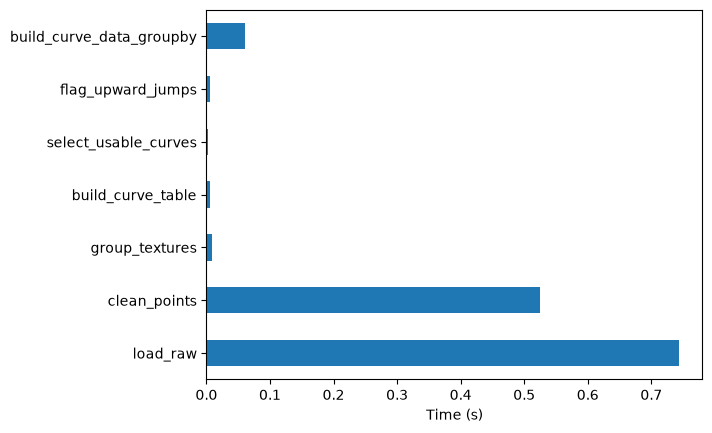

In [7]:
points, steps = clean_points(raw)
labelled = group_textures(points)
curve_table = build_curve_table(labelled)
usable, selected_points = select_usable_curves(curve_table, labelled)

times = {
    "load_raw": measure(load_raw, repeats=1),
    "clean_points": measure(clean_points, raw, repeats=1),
    "group_textures": measure(group_textures, points),
    "build_curve_table": measure(build_curve_table, labelled),
    "select_usable_curves": measure(select_usable_curves, curve_table, labelled),
    "flag_upward_jumps": measure(flag_upward_jumps, usable, selected_points),
    "build_curve_data_groupby": measure(build_curve_data_groupby, selected_points),
}
times = pd.Series(times)
print((times).round(3))
times.plot.barh()
plt.xlabel("Time (s)")
plt.show()

The reading of the file (`load_raw`) and `clean_points` take most of the time. Both are the O(R c) steps of the analysis. The steps after the cleaning work with only 10 thousand rows or less, so they are fast.

## 5. Summary

| Algorithm | Time |
|---|---|
| `load_raw` | O(R c) |
| `clean_points` | O(R c) |
| `group_textures` | O(R_t c) |
| `build_curve_table` | O(R_t + C log C) |
| `select_usable_curves` | O(R_t + C) |
| `flag_upward_jumps` | O(R_s log R_s) |
| `build_curve_data` (first version) | O(C R_s) |
| `build_curve_data_groupby` (optimized) | O(R_s) |